# Маркетплейс: онлайн торговля
**Условие задачи:** мы можем реализовать некий товар по двум ценам: $ price_1 = 100$, $price_2 = 200$ (в общем случае, товар может быть реализован по любой цене). При этом накладные расходы (сюда включается себестоимость, доставка, реклама и т.д.) состаляют 50. Необходимо определить цену, по которой мы получим больше прибыли. При этом спрос на товар определяется распределением Пуассона со следующими параметрами:  

- Мат. ожидание спроса (количество покупок за день) по цене 100: $order_1 = 5$
- Мат. ожидание спроса по цене 200: $order_2 = 2$

Найти оптимальную цену продажи, используя следующие стратегии:
- эпсилон жадной стратегия
- оптимизм в неопределенности
- UCB1
- выборка Томпсона

**Оценивание решения:** за каждую реализованную стратегию начисляется **5 баллов**. Также в конце необходимо написать **краткий отчет**, который оценивается в **7 баллов**. Таким образом, за рещение задачи в сумме можно получить **27 баллов**.

Решение по материалам bandits.ipynb. Сравниваем стратегии по накопленной прибыли и псевдосожалению. Истинные интенсивности используются только симулятором и для оценки качества, но не для выбора цены.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gamma
from IPython.display import display
N = 120
prices = np.array([100, 200])
costs = 50
margin = prices - costs
orders = np.array([5., 2.])
expected = orders * margin
optim_reward = expected.max()
print('Ожидаемая прибыль по ценам:', expected)
print('Оптимальная цена:', prices[expected.argmax()])

Ожидаемая прибыль по ценам: [250. 300.]
Оптимальная цена: 200


## 1. Эпсилон-жадная стратегия
После одного наблюдения каждой цены с вероятностью 0,1 выбираем случайную цену, иначе цену с максимальной эмпирической средней прибылью.

In [2]:
def epsilon_greedy(counts, sums, rng, t):
    if t < 2:
        return t
    if rng.random() < 0.1:
        return rng.integers(2)
    return np.argmax(sums * margin / counts)

## 2. Оптимизм в неопределенности
Начальная фиктивная прибыль 20000 учитывается при выборе, но не включается в реальную прибыль и число дней. Как в семинаре, оптимистическая оценка постепенно уменьшается.

In [3]:
def optimistic(counts, sums, rng, t):
    return np.argmax((20000 + sums * margin) / (counts + 1))

## 3. UCB для пуассоновского спроса
По подсказке задания применяем правило трёх сигм к оценке интенсивности: $UCB_j=(p_j-50)(\hat\lambda_j+3\sqrt{\hat\lambda_j/(n_j+1)})$. Это адаптация UCB к пуассоновской модели, а не классический UCB1 для ограниченных наград. Нулевая оценка спроса даёт нулевую границу; чтобы избежать вырождения, используем минимальную оценку дисперсии 1/n только при нулевом среднем.

In [4]:
def poisson_ucb(counts, sums, rng, t):
    if t < 2:
        return t
    mean = sums / counts
    variance = np.where(mean > 0, mean, 1 / counts)
    return np.argmax(margin * (mean + 3*np.sqrt(variance/(counts+1))))

## 4. Выборка Томпсона
Используем априорные параметры из задания: $\alpha=(4,3)$, $\beta=(1,1)$ (rate). После наблюдения спроса $y$ обновляем $\alpha_j\leftarrow\alpha_j+y$, $\beta_j\leftarrow\beta_j+1$. Выбираем цену по максимальной сэмплированной прибыли, а не по максимальному спросу. Исходный пример с Beta–Bernoulli из семинара заменён сопряжённой Gamma–Poisson моделью.

In [5]:
def thompson(counts, sums, rng, t):
    if t < 2:
        return t
    alpha = np.array([4., 3.]) + sums
    beta = 1 + counts
    sampled = rng.gamma(alpha, 1/beta)
    return np.argmax(sampled * margin)

## 5. Симуляция и сравнение
Для всех стратегий используем 120 дней (в задании для Томпсона отдельно указан горизонт 365; его проверим дополнительно). Реализованная прибыль случайна, поэтому дополнительно считаем псевдосожаление: сумму разностей между максимальной ожидаемой прибылью и ожидаемой прибылью выбранной цены.

In [6]:
strategies = {'Эпсилон-жадная': epsilon_greedy, 'Оптимизм': optimistic,
              'UCB (Пуассон)': poisson_ucb, 'Томпсон': thompson}
def simulate(strategy, days=N, seed=42):
    rng = np.random.default_rng(seed)
    demand = rng.poisson(orders, size=(days,2))
    counts = np.zeros(2, dtype=int)
    sums = np.zeros(2)
    choices, rewards = [], []
    for t in range(days):
        j = strategy(counts, sums, rng, t)
        y = demand[t,j]
        counts[j] += 1
        sums[j] += y
        choices.append(j)
        rewards.append(y * margin[j])
    choices = np.array(choices)
    rewards = np.array(rewards)
    means = np.divide(sums*margin, counts, out=np.zeros(2), where=counts>0)
    return dict(counts=counts, sums=sums, means=means, rewards=rewards,
                regret=np.cumsum(optim_reward-expected[choices]),
                realized_regret=np.cumsum(optim_reward-rewards))
results = {name: simulate(fn) for name,fn in strategies.items()}
rows=[]
for name,r in results.items():
    assert r['counts'].sum() == N
    rows.append([name,*r['counts'],*r['means'],r['rewards'].sum(),r['regret'][-1]])
display(pd.DataFrame(rows,columns=['Стратегия','Дни 100','Дни 200','Средняя прибыль 100','Средняя прибыль 200','Прибыль','Псевдосожаление']).round(2))

,Стратегия,Дни 100,Дни 200,Средняя прибыль 100,Средняя прибыль 200,Прибыль,Псевдосожаление
0,Эпсилон-жадная,10,110,245.00,275.45,32750,500.0
1,Оптимизм,53,67,206.60,277.61,29550,2650.0
2,UCB (Пуассон),18,102,269.44,286.76,34100,900.0
3,Томпсон,39,81,275.64,279.63,33400,1950.0


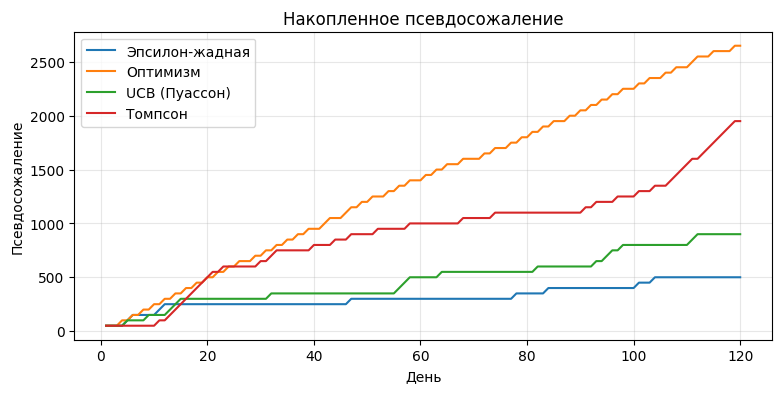

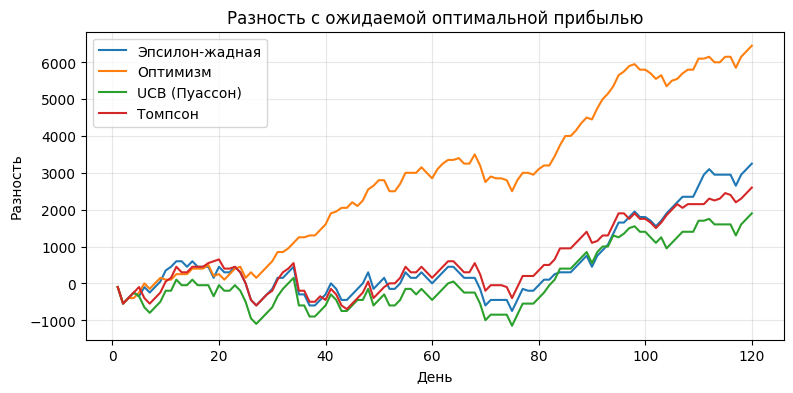

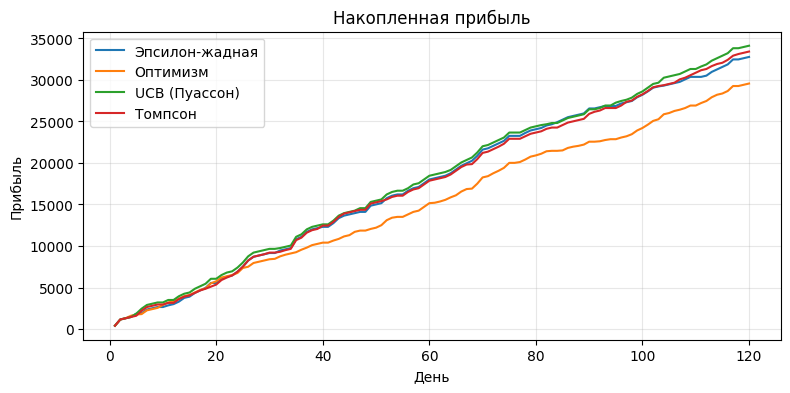

In [7]:
for key, title, ylabel in [('regret','Накопленное псевдосожаление','Псевдосожаление'),
                           ('realized_regret','Разность с ожидаемой оптимальной прибылью','Разность'),
                           ('rewards','Накопленная прибыль','Прибыль')]:
    plt.figure(figsize=(9,4))
    for name,r in results.items():
        plt.plot(np.arange(1,N+1), np.cumsum(r[key]) if key=='rewards' else r[key],label=name)
    plt.title(title); plt.xlabel('День'); plt.ylabel(ylabel); plt.grid(alpha=.3); plt.legend(); plt.show()

## 6. Апостериорные распределения Томпсона (365 дней)

Дни по ценам: [124 241]
Средняя наблюдаемая прибыль: [261.29032258 283.19502075]
Апостериорные средние спроса: [5.216      1.89256198]


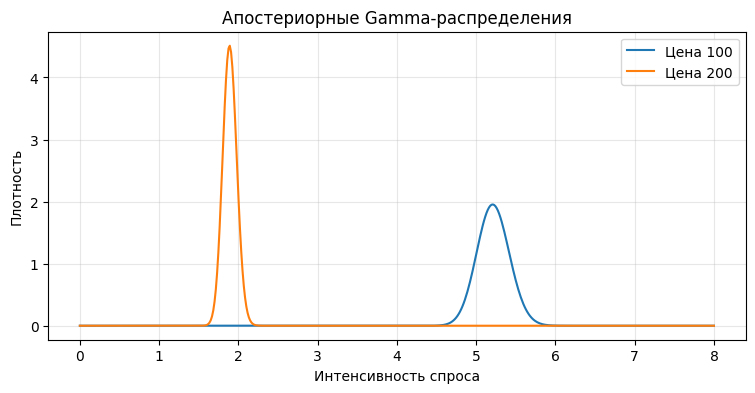

In [8]:
r = simulate(thompson, days=365)
alpha = np.array([4.,3.])+r['sums']
beta = 1+r['counts']
print('Дни по ценам:', r['counts'])
print('Средняя наблюдаемая прибыль:', r['means'])
print('Апостериорные средние спроса:', alpha/beta)
x = np.linspace(0,8,500)
plt.figure(figsize=(9,4))
for j in range(2):
    plt.plot(x,gamma.pdf(x,alpha[j],scale=1/beta[j]),label=f'Цена {prices[j]}')
plt.xlabel('Интенсивность спроса'); plt.ylabel('Плотность'); plt.title('Апостериорные Gamma-распределения'); plt.legend(); plt.grid(alpha=.3); plt.show()

## 7. Устойчивость результатов
Один прогон не позволяет надёжно определить лучшую стратегию. Выполним 300 независимых симуляций с одинаковыми наборами потенциального спроса для всех стратегий.

,Стратегия,Средняя прибыль,Среднее псевдосожаление,Стандартная ошибка сожаления,Доля дней с ценой 200
3,Томпсон,34834.000,1214.000,68.736,0.798
2,UCB (Пуассон),34879.833,1259.167,109.276,0.790
0,Эпсилон-жадная,33763.000,2339.833,126.618,0.610
1,Оптимизм,33200.500,2784.167,8.005,0.536


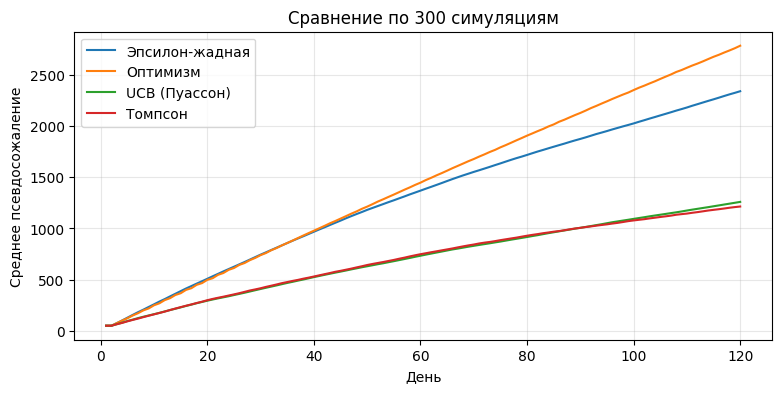

Лучшая стратегия по среднему псевдосожалению: Томпсон


In [9]:
R=300
summary=[]
curves={}
for name,fn in strategies.items():
    runs=[simulate(fn,seed=i) for i in range(R)]
    regrets=np.array([r['regret'] for r in runs])
    profits=np.array([r['rewards'].sum() for r in runs])
    curves[name]=regrets.mean(axis=0)
    summary.append([name,profits.mean(),regrets[:,-1].mean(),regrets[:,-1].std(ddof=1)/np.sqrt(R),np.mean([r['counts'][1]/N for r in runs])])
report=pd.DataFrame(summary,columns=['Стратегия','Средняя прибыль','Среднее псевдосожаление','Стандартная ошибка сожаления','Доля дней с ценой 200']).sort_values('Среднее псевдосожаление')
display(report.round(3))
plt.figure(figsize=(9,4))
for name,curve in curves.items(): plt.plot(np.arange(1,N+1),curve,label=name)
plt.xlabel('День'); plt.ylabel('Среднее псевдосожаление'); plt.title('Сравнение по 300 симуляциям'); plt.legend(); plt.grid(alpha=.3); plt.show()
print('Лучшая стратегия по среднему псевдосожалению:', report.iloc[0]['Стратегия'])

In [10]:
best=report.iloc[0]
print(f"Минимальное среднее псевдосожаление: {best['Стратегия']} ({best['Среднее псевдосожаление']:.2f}).")

Минимальное среднее псевдосожаление: Томпсон (1214.00).


## 8. Выводы
Теоретически выгоднее цена 200: ожидаемая дневная прибыль составляет 300 против 250 при цене 100. Несмотря на меньший спрос, большая маржа компенсирует снижение числа покупок.

Эпсилон-жадный алгоритм прост, но продолжает случайное исследование даже после получения информации. Оптимизм стимулирует начальное исследование, однако зависит от выбранной фиктивной награды. UCB учитывает неопределённость оценки спроса; использованная нормальная аппроксимация является приближением. Выборка Томпсона учитывает неопределённость интенсивности через сопряжённое гамма-распределение и выбирает цену по ожидаемой прибыли.

Сравнение стратегий проводится по среднему псевдосожалению на 300 прогонах, а не по случайной прибыли одного прогона. Результаты относятся к заданным интенсивностям, априорным параметрам и горизонту; универсального превосходства одной стратегии они не доказывают.

Многоруких бандитов можно применять при выборе рекламных объявлений, рекомендациях товаров, оптимизации интерфейсов и распределении трафика между вариантами. В реальной торговле также необходимо учитывать сезонность, изменение спроса и ограничения запасов.

**Результат эксперимента:** Минимальное среднее псевдосожаление: Томпсон (1214.00).